# Pedrógão Grande, Portugal wildfires 2017 - Proposal

## Introduction

- On 17th June 2017, multiple wildfires began all over Portugal with many in the Pedrógão Grande region. The fires spread and led to the deaths of at least 66 people and injury of 204 more.
- 2025 was the worst year on record for wildfires in Europe with considerably more area burnt than the 2006-2025 average.
- Wildfires have damaging human, environmental, economical and social effects.
    - Physical health, mental health, vulnerable groups particularly at risk.
    - Air/water pollution, habitat destruction, soil errosion, carbon feedback loops.
    - Property and infrastructure damage, industry disruption, public expenditure.

![Wildfires](burnt-area-in-eu.png)
https://joint-research-centre.ec.europa.eu/scientific-activities/natural-and-man-made-hazards/forest-fires/current-wildfire-situation-europe_en

## Aims

Some ideas of areas to explore.

- Classify land use change of the affected area.
- Use NBR/NDVI/dNBR to identify what areas were burned.
- Quantify how much land was affected using thresholds.
- Use these metrics to track the recovery of the area and/or sub-areas or other sites.
- Want to determine if this event was preceeded by unusual weather/climate conditions e.g. drought, hot weather. Using secondary data such as ERA5.
- Fit a statistical model to estimate recovery trajectories?, accounting for seasonal patterns?
- Compare different parts of the burn scar, such as areas with high and low initial disturbance.
- Compare the speed of recovery for different areas. Could there be a link between rainfall and speed of recovery?

## Data

- Landsat has good quality satellite imagery of the location over relevant timescales. The fire happened 17/06/2017 so there are 9 years of data following the event.
- Have located burn area perimeters from ICNF website.
- ERA5 data could be used to analyse the climatic conditions before and following the event. 

### Functions/Code

Code to load the Landsat data.

In [7]:
def find_sat_items(aoi_name, bbox, daterange, max_cloud_percent = 20, show = True):
    
    # Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
    # For example, "landsat-c2-l2" for Landsat Collection 2 Level 2 data.
    # See https://planetarycomputer.microsoft.com/CATALOG for more examples
    collection = "landsat-c2-l2"

    aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")
    if show == True:
        aoi.explore()

    # Connect to the MPC
    stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"
    
    catalog = pystac_client.Client.open(
        stac_url,
        modifier=planetary_computer.sign_inplace,  # only needed for MPC
    
        )

    # Search for cloud-free Landsat imagery in Summer
    search = catalog.search(
        collections=[collection],
        bbox=bbox,
        datetime=daterange,
        query={
            "eo:cloud_cover": {"lt": max_cloud_percent},  # Cloud cover less than 15%
            }, 
        sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}]
    )
    
    # Convert the search result object into a list of `pystac.Item` objects
    items = search.item_collection()
    if show == True:
        print(f"Found {len(items)} matching scene(s).")

    return items


def load_sat_data(item, bands, bbox):
    # Load requested bands directly into an xarray.Dataset using odc-stac
    ds = odc.stac.load(
        [item],
        bands=bands,
        bbox=bbox,
        # crs="EPSG:XXXX",  # Not used for now: by default, will use the native projection of the imagery
        # resolution=30, # Not used for now: by default, will use the native resolution of the imagery
    ).squeeze()
    
    # xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
    # The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
    ds.compute()

    # stack variables into a band dimension
    ds = ds.to_array(dim="band").squeeze()
    
    # add the band names as a long_name attribute to the dataset
    ds.attrs["long_name"] = list(ds["band"].values)

    # set zero to NaN
    ds = ds.where(ds > 0)
    
    # Surface reflectance scaling values
    ds = ds * 0.0000275 - 0.2  # convert to SR

    return ds


def plot_sat_data(ds):
    
    rgb = ds.sel(band=["red", "green", "blue"])
    fig, ax = plt.subplots()
    rgb.plot.imshow(ax=ax, robust=True)
    ax.set_aspect("equal")


def ndbi(ds):
    ndbi = (ds.sel(band="blue") - ds.sel(band="red")) / (ds.sel(band="blue") + ds.sel(band="red"))
    #ndbi.plot.imshow(cmap="BrBG", robust=True)

    return ndbi


def ndvi(ds):
    ndvi = (ds.sel(band="nir08") - ds.sel(band="red")) / (ds.sel(band="nir08") + ds.sel(band="red"))
    #ndvi.plot.imshow(cmap="BrBG", robust=True)

    return ndvi

def nbr(ds):
    nbr = (ds.sel(band="nir08") - ds.sel(band="swir16")) / (ds.sel(band="nir08") + ds.sel(band="swir16"))
    #nbr.plot.imshow(cmap="BrBG", robust=True)

    return nbr

In [3]:
import pystac_client
import planetary_computer
import odc.stac

import rioxarray as rxr
import geopandas as gpd
import matplotlib.pyplot as plt

from shapely import box

In [9]:
bbox = [-8.38, 39.78, -7.72, 40.15]

bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    'swir16',  # band 6, shortwave infrared 1
    'swir22',  # band 7, shortwave infrared 2
]

#Below we find satellite imagery of the burn site on 1st July 2017. 
#The wildfire is reported to have started on 17th June 2017 - approximately 2 weeks earlier.
items = find_sat_items("portugal", bbox, "2017-06-17/2017-07-15", max_cloud_percent = 20, show = True)

post_burn = load_sat_data(items[3], bands, bbox)

post_burn_rgb = post_burn.sel(band=["red", "green", "blue"])
post_burn_nbr = nbr(post_burn)

Found 8 matching scene(s).


In [14]:
# We have located below the same site but before the wildfire incident. 
#This imagery is from 15th of June 2017 - 2 days before the fire reportedly started.
items = find_sat_items("portugal", bbox, "2017-06-01/2017-06-17", max_cloud_percent = 20, show = True)

pre_burn = load_sat_data(items[3], bands, bbox)

pre_burn_rgb = pre_burn.sel(band=["red", "green", "blue"])
pre_burn_nbr = nbr(pre_burn)

Found 4 matching scene(s).


In [25]:
items = find_sat_items("portugal", bbox, "2020-06-01/2020-07-28", max_cloud_percent = 20, show = True)

three_year_post = load_sat_data(items[3], bands, bbox)

three_yr_rgb = three_year_post.sel(band=["red", "green", "blue"])
three_yr_nbr = nbr(three_year_post)

Found 15 matching scene(s).


### Graphs

Here I generate some initial graphs to show the event is identifiable. 

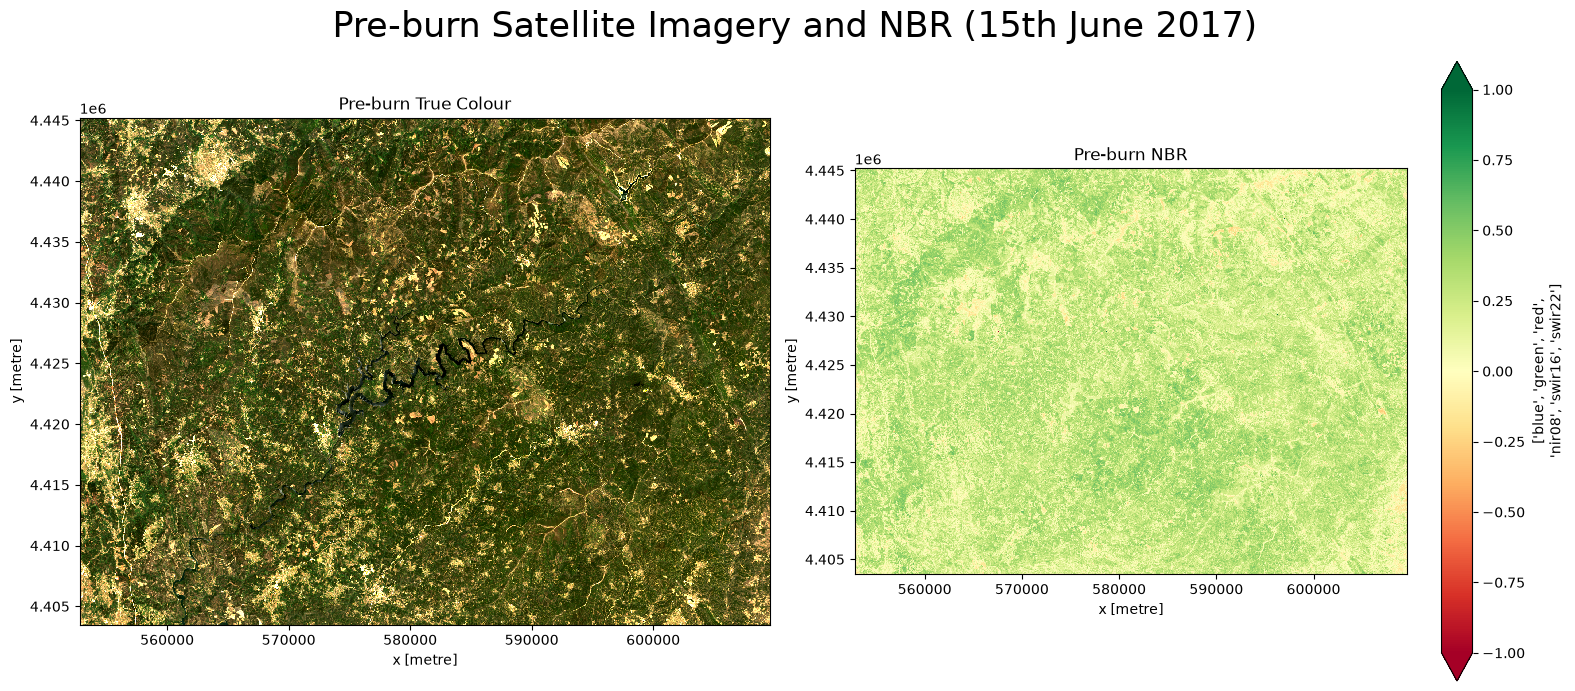

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Pre-burn Satellite Imagery and NBR (15th June 2017)", fontsize=25)


# Left: true/visual colour image
pre_burn_rgb.plot.imshow(ax=axes[0], robust=True)
axes[0].set_title("Pre-burn True Colour")
axes[0].set_aspect("equal")


# Right: NBR image
pre_burn_nbr.plot.imshow(ax=axes[1], cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("Pre-burn NBR")
axes[1].set_aspect("equal")


plt.tight_layout()
plt.show()

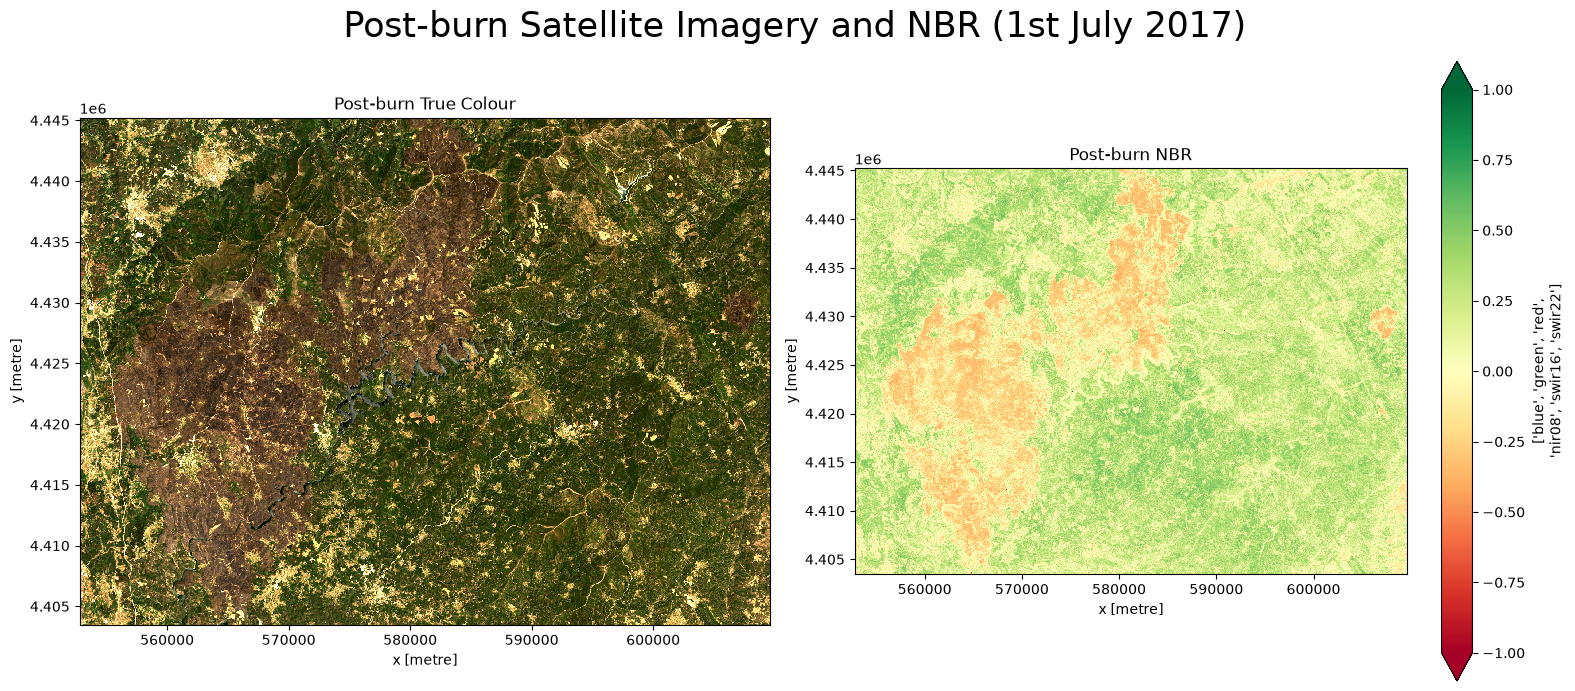

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Post-burn Satellite Imagery and NBR (1st July 2017)", fontsize=25)


# Left: true/visual colour image
post_burn_rgb.plot.imshow(ax=axes[0], robust=True)
axes[0].set_title("Post-burn True Colour")
axes[0].set_aspect("equal")


# Right: NBR image
post_burn_nbr.plot.imshow(ax=axes[1], cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("Post-burn NBR")
axes[1].set_aspect("equal")


plt.tight_layout()
plt.show()

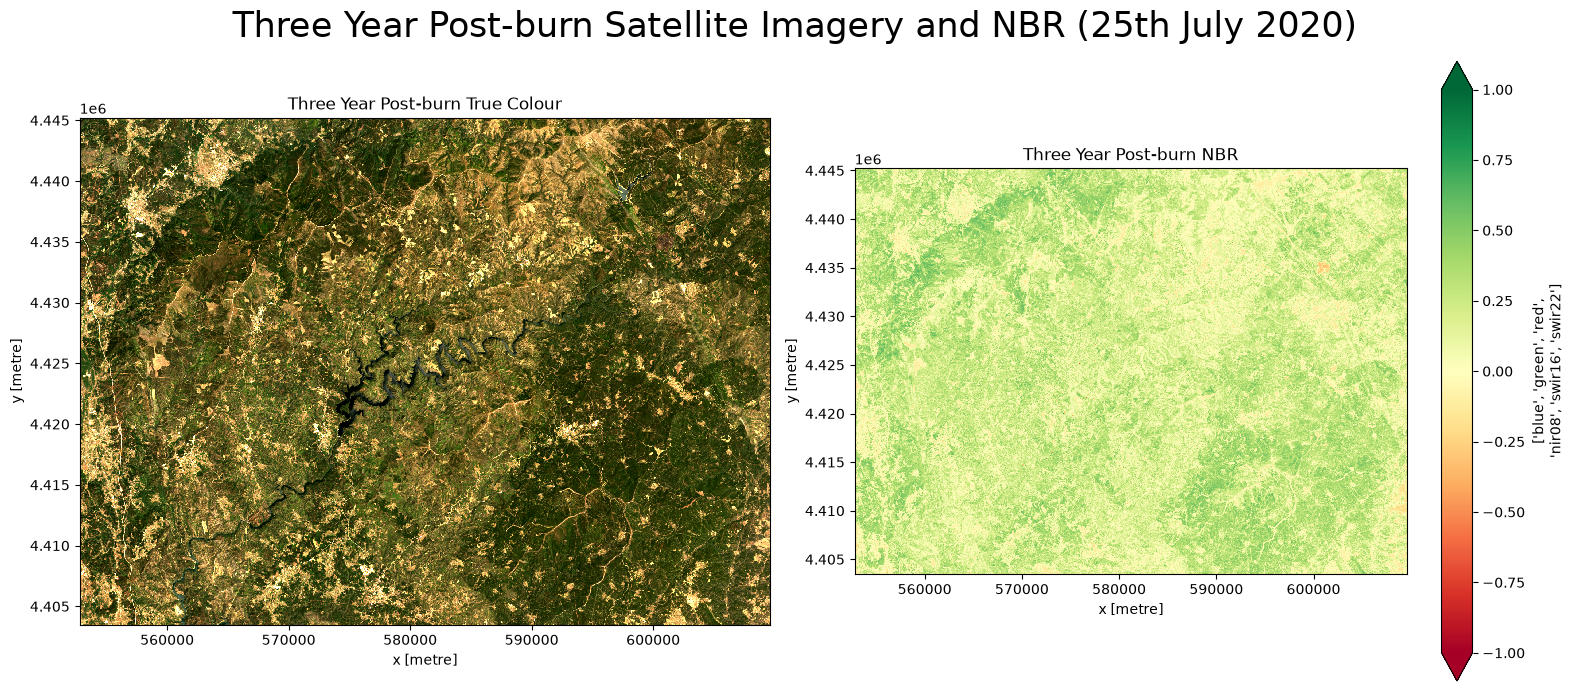

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Three Year Post-burn Satellite Imagery and NBR (25th July 2020)", fontsize=25)


# Left: true/visual colour image
three_yr_rgb.plot.imshow(ax=axes[0], robust=True)
axes[0].set_title("Three Year Post-burn True Colour")
axes[0].set_aspect("equal")


# Right: NBR image
three_yr_nbr.plot.imshow(ax=axes[1], cmap="RdYlGn", vmin=-1, vmax=1)
axes[1].set_title("Three Year Post-burn NBR")
axes[1].set_aspect("equal")


plt.tight_layout()
plt.show()

## Additioinal ideas

- NBR recovers quicker than NDVI. What is the difference here? Can track both of these and compare.
- What climate conditions preceed wildfire? Dry previous winter? Warm summer? Can we test these? Find another example/control to compare against.

Modelling recovery: (Chuds thinks this may be doing too much)
- Split the area into 100m grid. Calculate rate of recovery rate for each square for each timestep. Also calculate average characteristics for each cell.
- Model recovery rate over time - linear, polynomial, exponential, etc.
- Model recovery rate over explanatory variables - multiple regression, other more complicated models to account for dependence and spatial autocorrelation. 


In depth to-do list: (Chuds thinks this may be doing too much)

1) Gather data for area of interest at multiple time stamps over interesting period of time (i.e. immediate pre-burn to 3 years post-burn)
2) Split area into grid of squares for each time stamp.
3) Calculate NDVI (or other index) for each square for each time stamp.
4) Model NDVI over time for each square (linear or otherwise). Could map the rate of recovery as thematic map. !What do I need to consider with regards to seasons?!
5) Gather/calculate explanatory variables into one dataframe along with rates for each square and time stamp.
6) Model NDVI against other variables to determine significance. At this point may want to split the data so some can be used to validate the model. 

New to-do list:
1) 